Krishna Kumar Trivedi B28 DMV6

Import Pandas and Matplotlib

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

Create a simple CSV dataset

In [ ]:
data = {
    'Date': ['2026-01-01','2026-01-02','2026-01-03','2026-01-04',
             '2026-01-05','2026-01-06','2026-01-07','2026-01-08'],
    'Region': ['North','South','East','West','North','South','East','West'],
    'Shopping_Mall': ['Mall A','Mall B','Mall C','Mall D',
                      'Mall A','Mall B','Mall C','Mall D'],
    'Product_Category': ['Electronics','Clothing','Food','Electronics',
                         'Clothing','Food','Electronics','Clothing'],
    'Sales_Amount': [5000, 3000, 2000, 4500, 3500, 2500, 6000, 4000]
}

df = pd.DataFrame(data)
df.to_csv('Retail_Sales_Data.csv', index=False)

Import and explore the CSV

In [ ]:
df = pd.read_csv('Retail_Sales_Data.csv')

print(df.head())
print(df.shape)
print(df.info())

         Date Region Shopping_Mall Product_Category  Sales_Amount
0  2026-01-01  North        Mall A      Electronics          5000
1  2026-01-02  South        Mall B         Clothing          3000
2  2026-01-03   East        Mall C             Food          2000
3  2026-01-04   West        Mall D      Electronics          4500
4  2026-01-05  North        Mall A         Clothing          3500
(8, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Date              8 non-null      object
 1   Region            8 non-null      object
 2   Shopping_Mall     8 non-null      object
 3   Product_Category  8 non-null      object
 4   Sales_Amount      8 non-null      int64 
dtypes: int64(1), object(4)
memory usage: 452.0+ bytes
None


Identify relevant variables

In [ ]:
print(df[['Region', 'Shopping_Mall', 'Product_Category', 'Sales_Amount']])

  Region Shopping_Mall Product_Category  Sales_Amount
0  North        Mall A      Electronics          5000
1  South        Mall B         Clothing          3000
2   East        Mall C             Food          2000
3   West        Mall D      Electronics          4500
4  North        Mall A         Clothing          3500
5  South        Mall B             Food          2500
6   East        Mall C      Electronics          6000
7   West        Mall D         Clothing          4000


Total sales by Region

In [ ]:
region_sales = df.groupby('Region')['Sales_Amount'].sum()

print(region_sales)

Region
East     8000
North    8500
South    5500
West     8500
Name: Sales_Amount, dtype: int64


Sales by Region and Shopping Mall

In [ ]:
region_mall_sales = df.groupby(['Region', 'Shopping_Mall'])['Sales_Amount'].sum()

print(region_mall_sales)

Region  Shopping_Mall
East    Mall C           8000
North   Mall A           8500
South   Mall B           5500
West    Mall D           8500
Name: Sales_Amount, dtype: int64


Sales by Product Category

In [ ]:
category_sales = df.groupby('Product_Category')['Sales_Amount'].sum()

print(category_sales)

Product_Category
Clothing       10500
Electronics    15500
Food            4500
Name: Sales_Amount, dtype: int64


Find Top-Performing Region

In [ ]:
top_region = region_sales.idxmax()

print("Top-performing region:", top_region)

Top-performing region: North


Bar Plot: Sales by Region

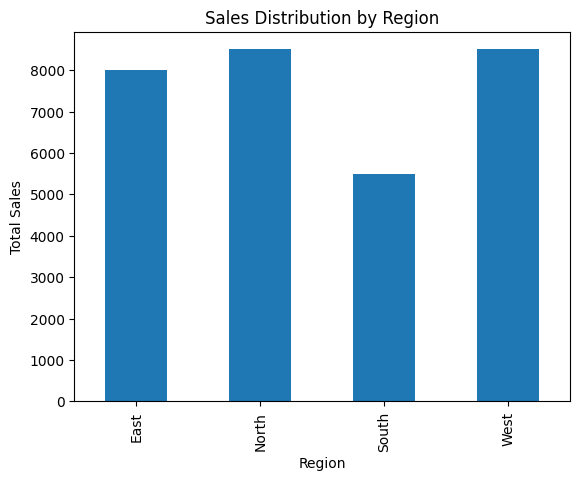

In [ ]:
region_sales.plot(kind='bar')

plt.title('Sales Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.show()

Bar Plot: Sales by Product Category

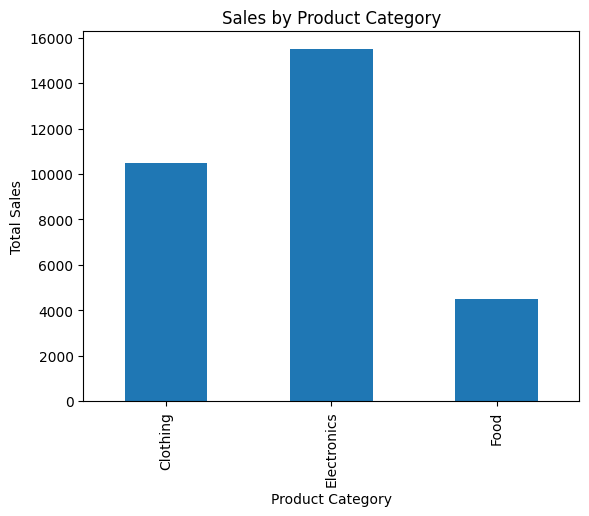

In [ ]:
category_sales.plot(kind='bar')

plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.show()

Region vs Product Category

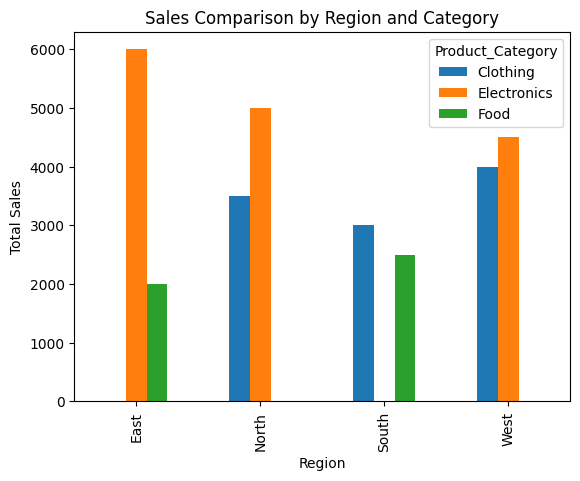

In [ ]:
comparison = df.pivot_table(
    values='Sales_Amount',
    index='Region',
    columns='Product_Category',
    aggfunc='sum'
)

comparison.plot(kind='bar')

plt.title('Sales Comparison by Region and Category')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.show()